# Bước 4. Data Analysis with Python: khám phá dữ liệu trước khi lập mô hình

Bước 3 dùng SQL để đếm và xếp hạng. Bước này dùng Python để trả lời 14 câu hỏi khám phá. Sáu câu đầu dẫn thẳng tới một quyết định ở Bước 6. Tám câu sau đi theo bốn góc nhìn mà môn ADY201m yêu cầu: chu kỳ, phân bố, quan hệ giữa các biến, và địa lý.

| STT | Mục | Câu hỏi | Quyết định ở Bước 6 mà câu trả lời dẫn tới |
|---|---|---|---|
| 1 | 4.1 | Các đặc trưng phân bố thế nào? | Mô hình tuyến tính, k-NN và MLP dùng log(1 + x) rồi chuẩn hoá |
| 2 | 4.2 | Mỗi đặc trưng một mình tách hai lớp tới đâu? | Thang đặc trưng phải tách riêng chỉ số tương đồng và nhóm trang |
| 3 | 4.3 | Cột của tác giả và cột nhóm tự tính có trùng thông tin không? | Đọc kết quả theo nhóm đặc trưng, không theo từng cột |
| 4 | 4.4 | Ở nhóm trang chủ, hai lớp còn khác nhau ở đâu? | Chấm riêng mọi mô hình trên nhóm trang chủ |
| 5 | 4.5 | Địa chỉ lừa đảo dùng chung tên miền nhiều cỡ nào? | Dùng cách chia theo tên miền bên cạnh chia phân tầng |
| 6 | 4.6 | Phần TLD chưa thấy khác phần đã thấy ở đặc trưng nào? | Thử trên TLD chưa thấy, có bộ đặc trưng bỏ thống kê TLD |
| 7 | 4.7 | Chu kỳ: dữ liệu có thứ tự thời gian hay thứ tự trong tệp không? | Không dùng thứ tự dòng, không có chia theo thời gian |
| 8 | 4.8 | Phân bố: độ dài địa chỉ ở ba nhóm khác nhau thế nào? | Báo cáo kết quả theo nhóm trang chủ và nhóm có đường dẫn |
| 9 | 4.9 | Phân bố: đuôi phải của độ dài dài cỡ nào? | Một ngưỡng độ dài cũng là một lối tắt, cần ghi trong bài |
| 10 | 4.10 | Quan hệ: tương quan với nhãn còn lại bao nhiêu ở nhóm trang chủ? | Bộ không thấy tiền tố phải bỏ `IsHTTPS` |
| 11 | 4.11 | Quan hệ: các lối tắt có trùng nhau không? | Bỏ một lối tắt chưa đủ, phải bỏ cả nhóm |
| 12 | 4.12 | Địa lý: tỷ lệ lừa đảo theo TLD mã nước? | TLD mã nước chỉ để mô tả, không làm đặc trưng mới |
| 13 | 4.13 | Địa lý: lối tắt có yếu đi theo loại TLD không? | Phép thử TLD chưa thấy không thay được việc bỏ cột |
| 14 | 4.14 | Trang lừa đảo nhỏ cỡ nào so với trang hợp lệ? | Nhóm đặc trưng trang được đọc như một lối tắt |

Hình ở bước này để KHÁM PHÁ, lưu trong `Figures/` với tên bắt đầu bằng `b4_`. Hình cho bài báo được vẽ ở Bước 5.
Mọi phép tính dùng bảng mô hình 235.370 dòng của Bước 2. Chữ trong hình bằng tiếng Anh, không có tiêu đề bên trong hình.

Ô dưới nạp thư viện, đọc bảng mô hình và danh sách nhóm đặc trưng của Bước 2, khai báo màu của bốn nhóm đặc trưng và tách sẵn nhóm trang chủ. Ô này in kích thước bảng.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from style import *
setup()
plt.rcParams.update({"font.size": 8.5})
OUT = "../Outputs/"
pd.set_option("display.width", 250)
pd.set_option("display.float_format", lambda v: f"{v:.6g}")
df = pd.read_parquet(OUT + "phishing_model_table.parquet")
groups = json.load(open(OUT + "feature_groups.json", encoding="utf-8"))
SHORTCUT, ADDRESS, PAGE, PREFIX_BLIND = groups["shortcut"], groups["address"], groups["page"], groups["prefix_blind"]
ALL = SHORTCUT + ADDRESS + PAGE + PREFIX_BLIND
GROUP_OF = {**{c: "shortcut" for c in SHORTCUT}, **{c: "address" for c in ADDRESS}, **{c: "page" for c in PAGE}, **{c: "prefix blind" for c in PREFIX_BLIND}}
COLOR_OF = {"shortcut": "black", "address": SKY, "page": GREY, "prefix blind": OURS}
y = df.phishing
home = df[df.homepage_only == 1]
CLASS = {0: "legitimate", 1: "phishing"}
print("Bảng mô hình:", df.shape, "| số đặc trưng theo nhóm:", {k: len(v) for k, v in [("shortcut", SHORTCUT), ("address", ADDRESS), ("page", PAGE), ("prefix blind", PREFIX_BLIND)]},
      "| nhóm trang chủ:", f"{len(home):,}", "dòng")

Bảng mô hình: (235370, 89) | số đặc trưng theo nhóm: {'shortcut': 1, 'address': 21, 'page': 28, 'prefix blind': 14} | nhóm trang chủ: 175,363 dòng


## 4.1 Các đặc trưng phân bố thế nào
Ô dưới vẽ hai biểu đồ tần suất của độ dài thật của địa chỉ, tách theo lớp: bên trái là độ dài (cắt ở 150 ký tự để nhìn rõ phần chính), bên phải là log(1 + độ dài). Ô cũng tính độ lệch (skewness) của 43 đặc trưng không phải cờ 0 hoặc 1.
Cách đọc: độ lệch càng lớn thì đuôi phải càng dài. Độ lệch trên 2 là rất lệch, khi ấy vài giá trị cực lớn sẽ lấn át mô hình tuyến tính và mô hình dựa trên khoảng cách.

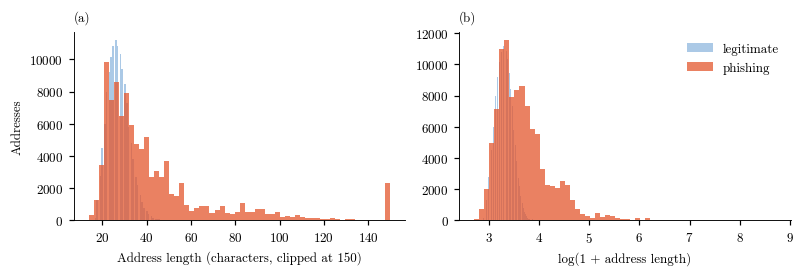

Số đặc trưng không phải cờ: 43 | trong đó lệch phải mạnh (độ lệch > 2): 30
Mười đặc trưng lệch nhất: {'NoOfCSS': 464.0, 'NoOfObfuscatedChar': 204.5, 'NoOfJS': 140.4, 'NoOfEqualsInURL': 114.9, 'pb_equals': 114.1, 'NoOfEmptyRef': 106.7, 'NoOfAmpersandInURL': 106.6, 'pb_hyphens': 102.2, 'NoOfiFrame': 97.6, 'NoOfDegitsInURL': 94.9}
Độ lệch của độ dài thật: 53.70 | sau log1p: 2.37


In [2]:
skew = df[ALL].skew().rename("do_lech")
counts = [c for c in ALL if df[c].nunique() > 2]                              # bỏ các cờ 0 hoặc 1
heavy = skew[counts][skew[counts] > 2].sort_values(ascending=False)
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), layout="constrained")
for cls, color in [(0, SKY), (1, OURS)]:
    v = df.loc[y == cls, "url_length_true"]
    axes[0].hist(v.clip(upper=150), bins=60, color=color, alpha=0.75, label=CLASS[cls])
    axes[1].hist(np.log1p(v), bins=60, color=color, alpha=0.75, label=CLASS[cls])
axes[0].set_xlabel("Address length (characters, clipped at 150)")
axes[0].set_ylabel("Addresses")
axes[1].set_xlabel("log(1 + address length)")
axes[1].legend(frameon=False)
panel(axes[0], "(a)")
panel(axes[1], "(b)")
save(fig, "b4_length_distribution")
print("Số đặc trưng không phải cờ:", len(counts), "| trong đó lệch phải mạnh (độ lệch > 2):", len(heavy))
print("Mười đặc trưng lệch nhất:", heavy.head(10).round(1).to_dict())
print("Độ lệch của độ dài thật: %.2f | sau log1p: %.2f" % (df.url_length_true.skew(), np.log1p(df.url_length_true).skew()))

**Nhận xét:** 30 trên 43 đặc trưng không phải cờ có độ lệch trên 2, cao nhất là `NoOfCSS` (464), `NoOfObfuscatedChar` (204,5) và `NoOfJS` (140,4). Độ dài thật của địa chỉ có độ lệch 53,70, sau khi lấy log(1 + x) chỉ còn 2,37. Hình (a) cho thấy lớp hợp lệ dồn trong khoảng 15 tới 40 ký tự còn lớp lừa đảo trải dài tới mức cắt 150. Hình (b) cho thấy sau khi lấy log, hai lớp vẫn chồng nhau ở phần giữa.
**Quyết định ở Bước 6:** logistic, SVM tuyến tính, k-NN và MLP nhận log(1 + x) của các đặc trưng không âm rồi mới chuẩn hoá. Mô hình cây không cần, vì cây chỉ so thứ tự.

## 4.2 Mỗi đặc trưng một mình tách hai lớp tới đâu
Ô dưới tính ROC-AUC của từng đặc trưng trong 64 đặc trưng khi dùng một mình làm điểm số, rồi vẽ 15 đặc trưng mạnh nhất, tô màu theo nhóm. ROC-AUC 0,5 là đoán bừa, 1 là tách trọn. Cột `auc_tach` lấy giá trị lớn hơn giữa AUC và 1 trừ AUC, vì một đặc trưng mà "nhỏ hơn thì lừa đảo" cũng tách tốt như "lớn hơn thì lừa đảo".
Cách đọc: đặc trưng nào một mình đã gần 1 thì mô hình dùng nó sẽ chạm trần mà không cần học gì thêm. Bảng đầy đủ lưu ở `Outputs/table_b4_single_feature_auc.csv`.

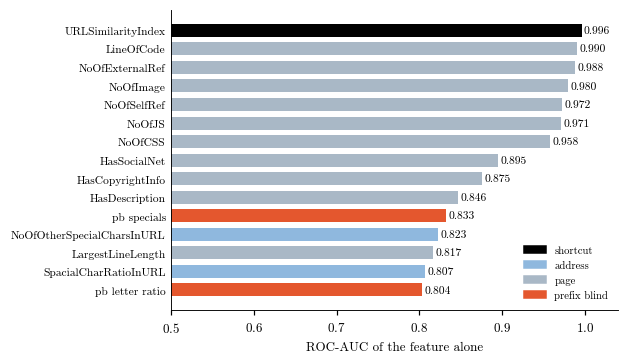

                                    nhom    auc  auc_tach                chieu
URLSimilarityIndex              shortcut 0.0039    0.9961  nhỏ hơn thì lừa đảo
LineOfCode                          page 0.0097    0.9903  nhỏ hơn thì lừa đảo
NoOfExternalRef                     page  0.012     0.988  nhỏ hơn thì lừa đảo
NoOfImage                           page 0.0203    0.9797  nhỏ hơn thì lừa đảo
NoOfSelfRef                         page 0.0275    0.9725  nhỏ hơn thì lừa đảo
NoOfJS                              page 0.0291    0.9709  nhỏ hơn thì lừa đảo
NoOfCSS                             page 0.0423    0.9577  nhỏ hơn thì lừa đảo
HasSocialNet                        page 0.1053    0.8947  nhỏ hơn thì lừa đảo
HasCopyrightInfo                    page 0.1245    0.8755  nhỏ hơn thì lừa đảo
HasDescription                      page 0.1537    0.8463  nhỏ hơn thì lừa đảo
pb_specials                 prefix blind 0.8326    0.8326  lớn hơn thì lừa đảo
NoOfOtherSpecialCharsInURL       address 0.8232    0

In [3]:
auc = pd.Series({c: roc_auc_score(y, df[c]) for c in ALL})
single = pd.DataFrame({"nhom": [GROUP_OF[c] for c in ALL], "auc": auc, "auc_tach": np.maximum(auc, 1 - auc),
                       "chieu": np.where(auc >= 0.5, "lớn hơn thì lừa đảo", "nhỏ hơn thì lừa đảo")}, index=ALL).sort_values("auc_tach", ascending=False)
single.round(4).to_csv(OUT + "table_b4_single_feature_auc.csv", index_label="feature")
top = single.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(5.6, 3.2), layout="constrained")
ax.barh([c.replace("_", " ") for c in top.index], top.auc_tach, color=[COLOR_OF[g] for g in top.nhom], height=0.7)
for k, v in enumerate(top.auc_tach):
    ax.text(v + 0.003, k, f"{v:.3f}", va="center", fontfamily=BOLD, fontsize=7.5)
ax.set_xlim(0.5, 1.04)
ax.set_xlabel("ROC-AUC of the feature alone")
ax.tick_params(axis="y", length=0, labelsize=7.5)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLOR_OF[g]) for g in COLOR_OF], labels=list(COLOR_OF), frameon=False, loc="lower right", fontsize=7)
save(fig, "b4_single_feature_auc")
print(single.head(15).round(4).to_string())
print("\nĐặc trưng một mình mạnh nhất của từng nhóm:", single.groupby("nhom").auc_tach.max().round(4).to_dict())
print("Số đặc trưng một mình đạt từ 0,95:", int((single.auc_tach >= 0.95).sum()), single.index[single.auc_tach >= 0.95].tolist())

**Nhận xét:** 7 đặc trưng một mình đã đạt ROC-AUC từ 0,95: chỉ số tương đồng (0,9961) và sáu đặc trưng trang, đứng đầu là `LineOfCode` (0,9903), `NoOfExternalRef` (0,988) và `NoOfImage` (0,9797). Đặc trưng địa chỉ mạnh nhất của tác giả chỉ đạt 0,8232 (`NoOfOtherSpecialCharsInURL`), đặc trưng không thấy tiền tố mạnh nhất đạt 0,8326 (`pb_specials`). Riêng `IsHTTPS` không có trong 15 đặc trưng đầu, vì một mình nó chỉ tách được nửa lớp lừa đảo dùng `http://`.
**Quyết định ở Bước 6:** thang đặc trưng phải tách riêng chỉ số tương đồng và nhóm trang. Mô hình nào được dùng một trong hai nhóm ấy sẽ chạm trần, nên so mô hình chỉ có nghĩa ở các bộ không có chúng.

## 4.3 Cột của tác giả và cột nhóm tự tính có trùng thông tin không
Ô dưới vẽ ma trận tương quan hạng Spearman của 14 đặc trưng: các cột địa chỉ của tác giả, các cột không thấy tiền tố tương ứng, chỉ số tương đồng và hai cột trang.
Cách đọc: ô càng đậm thì hai cột càng đi cùng nhau. Hai cột tương quan gần 1 mang gần như cùng một thông tin, nên mô hình dùng cột nào cũng như nhau.

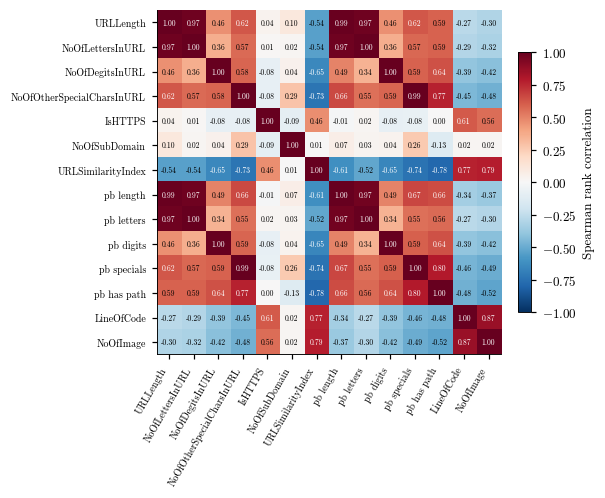

Sáu cặp tương quan mạnh nhất:
NoOfDegitsInURL             pb_digits          0.999
NoOfLettersInURL            pb_letters         0.999
NoOfOtherSpecialCharsInURL  pb_specials        0.994
URLLength                   pb_length          0.989
NoOfLettersInURL            pb_length          0.972
URLLength                   NoOfLettersInURL   0.972

Tương quan giữa cột của tác giả và cột nhóm tự tính: URLLength với pb_length 0.989 | NoOfLettersInURL với pb_letters 0.999 | NoOfDegitsInURL với pb_digits 0.999


In [4]:
cols = ["URLLength", "NoOfLettersInURL", "NoOfDegitsInURL", "NoOfOtherSpecialCharsInURL", "IsHTTPS", "NoOfSubDomain", "URLSimilarityIndex",
        "pb_length", "pb_letters", "pb_digits", "pb_specials", "pb_has_path", "LineOfCode", "NoOfImage"]
corr = df[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.4, 4.6), layout="constrained")
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(cols)))
ax.set_yticks(range(len(cols)))
ax.set_xticklabels([c.replace("_", " ") for c in cols], rotation=60, ha="right", fontsize=6.5)      # phông Computer Modern không có dấu gạch dưới
ax.set_yticklabels([c.replace("_", " ") for c in cols], fontsize=6.5)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=5, color="white" if abs(corr.iloc[i, j]) > 0.6 else "black")
fig.colorbar(im, ax=ax, shrink=0.7, label="Spearman rank correlation")
save(fig, "b4_feature_correlation")
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), 1)).stack().sort_values(key=abs, ascending=False)
print("Sáu cặp tương quan mạnh nhất:")
print(pairs.head(6).round(3).to_string())
print("\nTương quan giữa cột của tác giả và cột nhóm tự tính: URLLength với pb_length %.3f | NoOfLettersInURL với pb_letters %.3f | NoOfDegitsInURL với pb_digits %.3f"
      % (corr.loc["URLLength", "pb_length"], corr.loc["NoOfLettersInURL", "pb_letters"], corr.loc["NoOfDegitsInURL", "pb_digits"]))

**Nhận xét:** mỗi cột của tác giả gần như trùng với cột nhóm tự tính: `NoOfDegitsInURL` với `pb_digits` 0,999, `NoOfLettersInURL` với `pb_letters` 0,999, `NoOfOtherSpecialCharsInURL` với `pb_specials` 0,994, `URLLength` với `pb_length` 0,989. Cột `IsHTTPS` và `NoOfSubDomain` không có cột tương ứng trong bộ không thấy tiền tố, vì chúng chính là thông tin về tiền tố.
**Quyết định ở Bước 6:** nếu bộ địa chỉ của tác giả và bộ không thấy tiền tố cho điểm khác nhau thì phần chênh không đến từ thông tin mới, mà đến từ `IsHTTPS`, `NoOfSubDomain`, hai cột thống kê TLD và lỗi tính độ dài. Kết quả được đọc theo nhóm đặc trưng, không theo độ quan trọng của từng cột, vì các cột trùng nhau sẽ chia nhau độ quan trọng.

## 4.4 Ở nhóm trang chủ, hai lớp còn khác nhau ở đâu
Ô dưới vẽ bốn đường phân bố tích luỹ (ECDF) trên 175.363 địa chỉ là trang chủ: độ dài sau khi cắt tiền tố, số chữ số, số gạch ngang và số dấu chấm trong tên máy chủ. Mỗi đường cho biết bao nhiêu phần trăm địa chỉ có giá trị nhỏ hơn hoặc bằng một mức.
Cách đọc: hai đường càng xa nhau thì đặc trưng càng tách hai lớp. Bảng in kèm ROC-AUC của từng đặc trưng khi dùng một mình trên nhóm này.

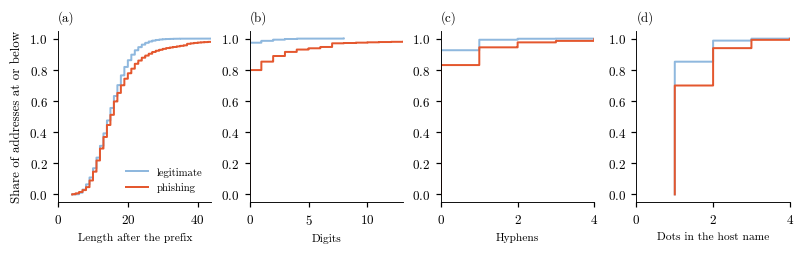

Nhóm trang chủ: 175,363 địa chỉ, 40,513 lừa đảo
   dac_trung  hop_le_trung_vi  lua_dao_trung_vi  hop_le_khac_0_pct  lua_dao_khac_0_pct  auc_mot_minh
   pb_length               15                15                100                 100          0.54
   pb_digits                0                 0               2.64              20.206         0.589
  pb_hyphens                0                 0              7.463              16.987         0.549
pb_host_dots                1                 1                100                 100         0.579


In [5]:
feats = ["pb_length", "pb_digits", "pb_hyphens", "pb_host_dots"]
labels = ["Length after the prefix", "Digits", "Hyphens", "Dots in the host name"]
fig, axes = plt.subplots(1, 4, figsize=(7.2, 2.2), layout="constrained")
rows = []
for ax, c, lab in zip(axes, feats, labels):
    for cls, color in [(0, SKY), (1, OURS)]:
        v = np.sort(home.loc[home.phishing == cls, c].to_numpy())
        ax.step(v, np.arange(1, len(v) + 1) / len(v), color=color, lw=1.3, label=CLASS[cls], where="post")
    ax.set_xlim(0, np.percentile(home[c], 99.5) + 1)
    ax.set_xlabel(lab, fontsize=7.5)
    rows.append(dict(dac_trung=c, hop_le_trung_vi=home.loc[home.phishing == 0, c].median(), lua_dao_trung_vi=home.loc[home.phishing == 1, c].median(),
                     hop_le_khac_0_pct=100 * (home.loc[home.phishing == 0, c] > 0).mean(), lua_dao_khac_0_pct=100 * (home.loc[home.phishing == 1, c] > 0).mean(),
                     auc_mot_minh=max(roc_auc_score(home.phishing, home[c]), 1 - roc_auc_score(home.phishing, home[c]))))
axes[0].set_ylabel("Share of addresses at or below")
axes[0].legend(frameon=False, fontsize=7)
for ax, p in zip(axes, "abcd"):
    panel(ax, f"({p})")
save(fig, "b4_homepage_ecdf")
print("Nhóm trang chủ:", f"{len(home):,}", "địa chỉ,", f"{int(home.phishing.sum()):,}", "lừa đảo")
print(pd.DataFrame(rows).round(3).to_string(index=False))

**Nhận xét:** ở nhóm trang chủ, hai lớp có cùng trung vị ở cả bốn đặc trưng (15 ký tự, 0 chữ số, 0 gạch ngang, 1 dấu chấm), và hai đường ECDF của độ dài và gạch ngang gần như chồng lên nhau; hai đường của chữ số và dấu chấm tách nhau rõ hơn nhưng chỉ ở phần nhỏ địa chỉ có giá trị khác 0 hoặc khác 1.. ROC-AUC khi dùng một mình chỉ từ 0,54 (độ dài) tới 0,589 (chữ số), sát mức đoán bừa 0,5. Khác biệt rõ nhất là tỷ lệ có chữ số (20,2% địa chỉ lừa đảo so với 2,6% địa chỉ hợp lệ) và có gạch ngang (17,0% so với 7,5%).
**Quyết định ở Bước 6:** mọi mô hình được chấm thêm một lần riêng trên nhóm trang chủ. Đây là nơi kết quả nói thật nhất về việc nhận ra lừa đảo từ chính tên miền, và nhóm dự kiến điểm số ở đây thấp hơn hẳn 99%.

## 4.5 Địa chỉ lừa đảo dùng chung tên miền nhiều cỡ nào
Ô dưới đếm, cho mỗi tên miền đăng ký, có bao nhiêu địa chỉ dùng tên miền ấy, gom thành bảy cỡ, rồi vẽ tỷ lệ địa chỉ của mỗi lớp rơi vào từng cỡ.
Cách đọc: cột "1" là địa chỉ có tên miền riêng, không chia với địa chỉ nào khác. Các cột bên phải là địa chỉ nằm trên tên miền dùng chung, chính là loại địa chỉ mà cách chia ngẫu nhiên đặt vào cả tập huấn luyện lẫn tập kiểm thử.

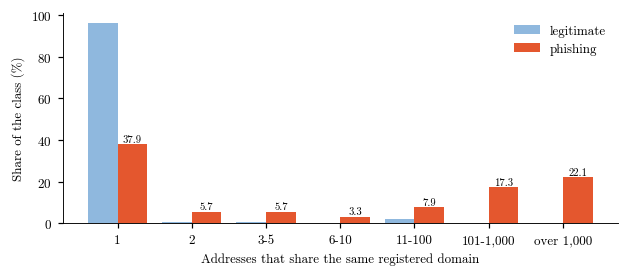

            so_ten_mien  so_dia_chi  lua_dao_tb_pct  ty_trong_dia_chi_pct
co                                                                       
1                167902      167902           22.71                 71.34
2                  3212        6424           88.81                  2.73
3-5                1848        6664           86.72                  2.83
6-10                526        3891           84.89                  1.65
11-100              423       10689           74.56                  4.54
101-1,000            59       17549           98.26                  7.46
over 1,000            7       22251             100                  9.45

Tỷ lệ địa chỉ nằm trên tên miền có từ 2 địa chỉ trở lên: hợp lệ 3.8% | lừa đảo 62.1%


In [6]:
per_domain = df.groupby("reg_domain").agg(dia_chi=("phishing", "size"), lua_dao=("phishing", "mean"))
bins = [1, 2, 3, 6, 11, 101, 1001, 10_000]
labels = ["1", "2", "3-5", "6-10", "11-100", "101-1,000", "over 1,000"]
per_domain["co"] = pd.cut(per_domain.dia_chi, bins, right=False, labels=labels)
table = per_domain.groupby("co", observed=True).agg(so_ten_mien=("dia_chi", "size"), so_dia_chi=("dia_chi", "sum"), lua_dao_tb_pct=("lua_dao", lambda v: 100 * v.mean()))
table["ty_trong_dia_chi_pct"] = 100 * table.so_dia_chi / len(df)
by_class = df.assign(co=df.reg_domain.map(per_domain.co)).groupby(["co", "phishing"], observed=True).size().unstack(fill_value=0)
share = 100 * by_class / by_class.sum()
fig, ax = plt.subplots(figsize=(5.6, 2.4), layout="constrained")
x = np.arange(len(share))
ax.bar(x - 0.2, share[0], 0.4, color=SKY, label="legitimate")
ax.bar(x + 0.2, share[1], 0.4, color=OURS, label="phishing")
for k in x:
    ax.text(k + 0.2, share[1].iloc[k] + 1, f"{share[1].iloc[k]:.1f}", ha="center", fontsize=7, fontfamily=BOLD)
ax.set_xticks(x)
ax.set_xticklabels(share.index)
ax.set_xlabel("Addresses that share the same registered domain")
ax.set_ylabel("Share of the class (%)")
ax.legend(frameon=False)
save(fig, "b4_domain_reuse")
print(table.round(2).to_string())
print("\nTỷ lệ địa chỉ nằm trên tên miền có từ 2 địa chỉ trở lên: hợp lệ %.1f%% | lừa đảo %.1f%%" % (100 - share[0].iloc[0], 100 - share[1].iloc[0]))

**Nhận xét:** 96,2% địa chỉ hợp lệ có tên miền riêng, nhưng chỉ 37,9% địa chỉ lừa đảo như vậy: 62,1% địa chỉ lừa đảo nằm trên tên miền có từ hai địa chỉ trở lên. Chỉ 7 tên miền có trên 1.000 địa chỉ, nhưng chúng giữ 22.251 địa chỉ (9,45% cả bảng) và toàn là lừa đảo. 59 tên miền cỡ 101 tới 1.000 địa chỉ giữ thêm 17.549 địa chỉ, và trung bình mỗi tên miền cỡ này có 98,26% địa chỉ là lừa đảo.
**Quyết định ở Bước 6:** ngoài chia phân tầng, mọi mô hình được chấm thêm trên cách chia theo tên miền của Bước 2. Nếu điểm số giảm khi chuyển sang cách chia này thì phần giảm là phần mô hình đã nhớ tên miền.

## 4.6 Phần TLD chưa thấy khác phần đã thấy ở đặc trưng nào
Ô dưới tính, cho từng đặc trưng địa chỉ và không thấy tiền tố, chênh lệch trung bình giữa phần TLD chưa thấy và phần TLD đã thấy (`com`, `org`, `net`), chia cho độ lệch chuẩn của lớp, làm riêng cho từng lớp. Hình vẽ 10 đặc trưng lệch nhiều nhất.
Cách đọc: chênh lệch trên 0,5 độ lệch chuẩn là lớn. Đặc trưng nào lệch mạnh thì mô hình học trên `com`, `org`, `net` sẽ gặp giá trị lạ ở phần còn lại. Bảng đầy đủ lưu ở `Outputs/table_b4_tld_shift.csv`.

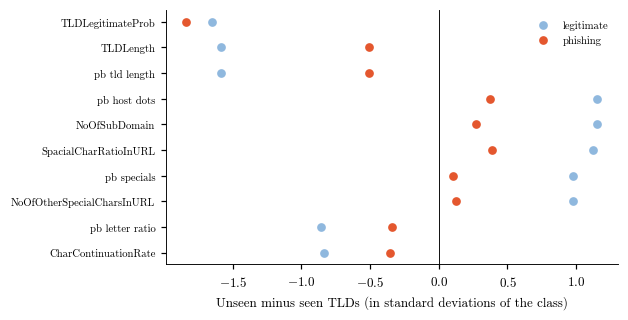

lop                         legitimate  phishing  lon_nhat
dac_trung                                                 
TLDLegitimateProb               -1.649    -1.835     1.835
TLDLength                       -1.585    -0.509     1.585
pb_tld_length                   -1.585     -0.51     1.585
pb_host_dots                     1.153     0.372     1.153
NoOfSubDomain                    1.153     0.274     1.153
SpacialCharRatioInURL            1.122     0.386     1.122
pb_specials                       0.98     0.102      0.98
NoOfOtherSpecialCharsInURL        0.98     0.125      0.98
pb_letter_ratio                 -0.853    -0.341     0.853
CharContinuationRate            -0.832    -0.351     0.832

Số đặc trưng lệch quá 0,5 độ lệch chuẩn ở ít nhất một lớp: 12 trên 35


In [7]:
seen, unseen = df[df.tld_seen == 1], df[df.tld_seen == 0]
rows = []
for c in ADDRESS + PREFIX_BLIND:
    for cls in (0, 1):
        a, b = seen.loc[seen.phishing == cls, c], unseen.loc[unseen.phishing == cls, c]
        sd = df.loc[df.phishing == cls, c].std()
        rows.append(dict(dac_trung=c, nhom=GROUP_OF[c], lop=CLASS[cls], chenh_chuan_hoa=(b.mean() - a.mean()) / sd if sd > 0 else 0.0))
shift = pd.DataFrame(rows)
wide = shift.pivot(index="dac_trung", columns="lop", values="chenh_chuan_hoa")
wide["lon_nhat"] = wide.abs().max(axis=1)
wide = wide.sort_values("lon_nhat", ascending=False)
wide.round(3).to_csv(OUT + "table_b4_tld_shift.csv")
top = wide.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(5.6, 2.8), layout="constrained")
yy = np.arange(len(top))
ax.axvline(0, color="black", lw=0.6)
ax.scatter(top.legitimate, yy, color=SKY, s=22, label="legitimate", zorder=3)
ax.scatter(top.phishing, yy, color=OURS, s=22, label="phishing", zorder=3)
ax.set_yticks(yy)
ax.set_yticklabels([c.replace("_", " ") for c in top.index], fontsize=7)
ax.set_xlabel("Unseen minus seen TLDs (in standard deviations of the class)")
ax.legend(frameon=False, fontsize=7)
save(fig, "b4_tld_shift")
print(wide.head(10).round(3).to_string())
print("\nSố đặc trưng lệch quá 0,5 độ lệch chuẩn ở ít nhất một lớp:", int((wide.lon_nhat > 0.5).sum()), "trên", len(wide))

**Nhận xét:** 12 trên 35 đặc trưng lệch quá 0,5 độ lệch chuẩn ở ít nhất một lớp. Lệch nhất là `TLDLegitimateProb` (-1,65 ở lớp hợp lệ, -1,84 ở lớp lừa đảo), vì cột này gán một con số cho mỗi TLD nên đổi hẳn giữa hai phần. Kế đó là độ dài TLD (-1,59 ở lớp hợp lệ) và số dấu chấm trong tên máy chủ (+1,15 ở lớp hợp lệ), vì các TLD mã nước hay đi kèm hai nhãn như `co.uk`.
Điểm đáng chú ý là lớp hợp lệ lệch nhiều hơn lớp lừa đảo ở hầu hết các đặc trưng: một mô hình học "địa chỉ hợp lệ trông như `abc.com`" sẽ dễ chặn nhầm địa chỉ hợp lệ dạng `abc.co.uk`.
**Quyết định ở Bước 6:** giữ phép thử TLD chưa thấy, đo cả tỷ lệ bắt được lẫn báo động giả, và có một bộ đặc trưng bỏ `TLDLegitimateProb` cùng `URLCharProb`.

## 4.7 Chu kỳ: dữ liệu có thứ tự thời gian hay thứ tự trong tệp không
Góc nhìn chu kỳ của môn học cần một trục thời gian. Bộ PhiUSIIL không có cột ngày, giờ hay năm nào, nên không thể xem mùa vụ hay xu hướng. Câu hỏi gần nhất còn trả lời được là: dòng trong tệp có được xếp theo thứ tự nào không, ví dụ toàn hợp lệ trước rồi toàn lừa đảo sau. Ô dưới chia tệp (đã bỏ trùng) thành các khối 10.000 dòng theo đúng thứ tự gốc và vẽ tỷ lệ lừa đảo của từng khối.
Cách đọc: đường phẳng quanh đường đứt (tỷ lệ chung 42,7%) nghĩa là hai lớp được trộn đều trong tệp. Một bậc thang nghĩa là tệp xếp theo lớp hay theo đợt thu thập.

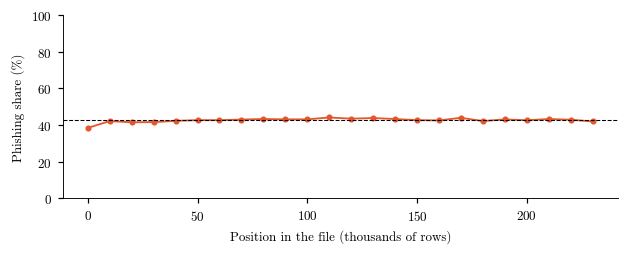

        dong_dau  so_dong  lua_dao_pct  trang_chu_pct
row_id                                               
0              0    10000         38.5           82.6
1          10000    10000         42.2           81.1
2          20000    10000         41.5           81.1
3          30000    10000         41.6           76.6
4          40000    10000         42.3           73.9
5          50000    10000         42.7           73.2
6          60000    10000         42.7             73
7          70000    10000           43             73
8          80000    10000         43.3           73.9
9          90000    10000         43.1           73.6
10        100000    10000         43.1           73.9
11        110000    10000         44.2           72.1
12        120000    10000         43.5           73.1
13        130000    10000         43.9           72.9
14        140000    10000         43.3           73.2
15        150000    10000         42.7             74
16        160000    10000   

In [8]:
order = df.row_id // 10_000                                                       # khối 10.000 dòng theo thứ tự trong tệp gốc (đã bỏ trùng)
blocks = df.groupby(order).agg(dong_dau=("row_id", "min"), so_dong=("row_id", "size"), lua_dao_pct=("phishing", lambda v: 100 * v.mean()),
                               trang_chu_pct=("homepage_only", lambda v: 100 * v.mean()))
fig, ax = plt.subplots(figsize=(5.6, 2.2), layout="constrained")
ax.plot(blocks.dong_dau / 1000, blocks.lua_dao_pct, color=OURS, marker="o", ms=3, lw=1.2, label="phishing share")
ax.axhline(100 * y.mean(), color="black", lw=0.7, ls="--")
ax.set_ylim(0, 100)
ax.set_xlabel("Position in the file (thousands of rows)")
ax.set_ylabel("Phishing share (%)")
save(fig, "b4_file_order")
first_half = df.row_id < len(df) // 2
print(blocks.round(1).to_string())
print("\nTỷ lệ lừa đảo: nửa đầu tệp %.2f%% | nửa sau %.2f%% | độ lệch chuẩn giữa các khối %.2f điểm %%" % (100 * y[first_half].mean(), 100 * y[~first_half].mean(), blocks.lua_dao_pct.std()))
print("Có cột thời gian nào trong bảng không:", any(k in c.lower() for c in df.columns for k in ("date", "time", "year")))

**Nhận xét:** bảng không có cột thời gian nào. Tỷ lệ lừa đảo của các khối dao động từ 38,5% (khối đầu) tới 44,2%, độ lệch chuẩn giữa các khối chỉ 1,12 điểm phần trăm, nửa đầu và nửa sau tệp gần bằng nhau (42,34% và 43,07%). Tỷ lệ trang chủ cao hơn ở bốn khối đầu (76,6% tới 82,6%) rồi đứng quanh 73%.
Tệp vì vậy đã được trộn, không có thứ tự thời gian hay thứ tự theo lớp để khai thác.
**Quyết định ở Bước 6:** không dùng thứ tự dòng làm đặc trưng và không có cách chia theo thời gian. Đây là giới hạn phải ghi trong bài: kết quả không nói gì về việc bộ lọc giữ được bao lâu khi kẻ lừa đảo đổi cách làm.

## 4.8 Phân bố: độ dài địa chỉ ở ba nhóm
Ô dưới vẽ biểu đồ hộp của độ dài sau khi cắt tiền tố cho ba nhóm: địa chỉ hợp lệ (đều là trang chủ), địa chỉ lừa đảo là trang chủ và địa chỉ lừa đảo có đường dẫn. Trục ngang dùng thang log, râu kéo tới phân vị 5% và 95%.
Cách đọc: hộp là nửa giữa của dữ liệu (phân vị 25% tới 75%), vạch đen trong hộp là trung vị. Hai hộp chồng nhau nghĩa là độ dài không tách được hai nhóm ấy.

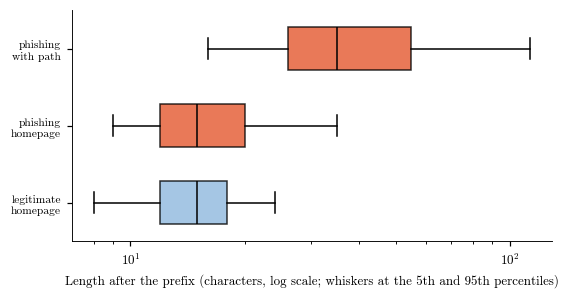

                     count  5%  25%  50%  75%  95%  max
legitimate homepage 134850   8   12   15   18   24   46
phishing homepage    40513   9   12   15   20   35  101
phishing with path   60007  16   26   35   55  113 6089


In [9]:
groups_plot = [("legitimate\nhomepage", (df.phishing == 0)), ("phishing\nhomepage", (df.phishing == 1) & (df.homepage_only == 1)), ("phishing\nwith path", (df.phishing == 1) & (df.homepage_only == 0))]
fig, ax = plt.subplots(figsize=(5.0, 2.6), layout="constrained")
data = [df.loc[m, "pb_length"] for _, m in groups_plot]
bp = ax.boxplot(data, orientation="horizontal", whis=(5, 95), showfliers=False, widths=0.55, patch_artist=True, medianprops=dict(color="black"))
for patch, color in zip(bp["boxes"], [SKY, OURS, OURS]):
    patch.set_facecolor(color)
    patch.set_alpha(0.8)
ax.set_yticks([1, 2, 3])
ax.set_yticklabels([g for g, _ in groups_plot], fontsize=7.5)
ax.set_xscale("log")
ax.set_xlabel("Length after the prefix (characters, log scale; whiskers at the 5th and 95th percentiles)")
save(fig, "b4_length_boxplot")
summary = pd.DataFrame({name.replace("\n", " "): df.loc[m, "pb_length"].describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]) for name, m in groups_plot}).T
print(summary[["count", "5%", "25%", "50%", "75%", "95%", "max"]].round(1).to_string())

**Nhận xét:** hộp của địa chỉ hợp lệ (12 tới 18 ký tự) và hộp của địa chỉ lừa đảo là trang chủ (12 tới 20 ký tự) gần như trùng nhau, cùng trung vị 15 ký tự. Hộp của địa chỉ lừa đảo có đường dẫn nằm hẳn bên phải (26 tới 55 ký tự, trung vị 35).
**Quyết định ở Bước 6:** kết quả được báo cáo riêng cho nhóm trang chủ, vì trên toàn bộ dữ liệu, khác biệt về độ dài chủ yếu là khác biệt giữa có và không có đường dẫn.

## 4.9 Phân bố: đuôi phải của độ dài
Ô dưới tính, cho ba nhóm của mục 4.8, tỷ lệ địa chỉ dài trên 20, 30, 50 và 100 ký tự sau khi cắt tiền tố, rồi so với địa chỉ hợp lệ dài nhất.
Cách đọc: nếu một nhóm có địa chỉ dài hơn mọi địa chỉ hợp lệ thì một quy tắc "dài hơn mức ấy là lừa đảo" bắt được chúng mà không báo động giả nào. Bảng lưu ở `Outputs/table_b4_length_tail.csv`.

In [10]:
limits = [20, 30, 50, 100]
rows = []
for name, m in [("legitimate", df.phishing == 0), ("phishing, homepage", (df.phishing == 1) & (df.homepage_only == 1)), ("phishing, with path", (df.phishing == 1) & (df.homepage_only == 0))]:
    rows.append({"nhom": name, **{f"tren_{k}_pct": 100 * (df.loc[m, "pb_length"] > k).mean() for k in limits}})
tail = pd.DataFrame(rows).set_index("nhom")
tail.round(2).to_csv(OUT + "table_b4_length_tail.csv")
print(tail.round(2).to_string())
longest_legit = df.loc[df.phishing == 0, "pb_length"].max()
print("\nĐịa chỉ hợp lệ dài nhất sau khi cắt tiền tố: %d ký tự | số địa chỉ lừa đảo dài hơn mức ấy: %d (%.1f%% lớp lừa đảo)"
      % (longest_legit, int((df.loc[df.phishing == 1, "pb_length"] > longest_legit).sum()), 100 * (df.loc[df.phishing == 1, "pb_length"] > longest_legit).mean()))

                     tren_20_pct  tren_30_pct  tren_50_pct  tren_100_pct
nhom                                                                    
legitimate                 13.88         0.39            0             0
phishing, homepage         22.25         6.59         0.46             0
phishing, with path        87.55        61.13        27.43          6.43

Địa chỉ hợp lệ dài nhất sau khi cắt tiền tố: 46 ký tự | số địa chỉ lừa đảo dài hơn mức ấy: 19466 (19.4% lớp lừa đảo)


**Nhận xét:** địa chỉ hợp lệ dài nhất chỉ có 46 ký tự sau khi cắt tiền tố, và chỉ 0,39% địa chỉ hợp lệ dài trên 30 ký tự. Trong khi đó 19.466 địa chỉ lừa đảo (19,4% lớp lừa đảo) dài hơn 46 ký tự, gần như toàn là địa chỉ có đường dẫn (27,43% nhóm này dài trên 50 ký tự). Ở nhóm lừa đảo là trang chủ, chỉ 0,46% dài trên 50 ký tự.
**Quyết định ở Bước 6:** "dài hơn 46 ký tự" cũng là một lối tắt không báo động giả trên dữ liệu này, vì lớp hợp lệ chỉ gồm trang chủ. Bài báo cần ghi rằng mọi đặc trưng về độ dài đều mang một phần lối tắt đường dẫn.

## 4.10 Quan hệ: tương quan với nhãn còn lại bao nhiêu ở nhóm trang chủ
Ô dưới tính độ lớn tương quan hạng của từng đặc trưng địa chỉ và không thấy tiền tố với nhãn, một lần trên toàn bộ dữ liệu và một lần chỉ trên nhóm trang chủ, rồi vẽ 14 đặc trưng mạnh nhất dạng quả tạ.
Cách đọc: chấm đen là toàn bộ, chấm san hô là nhóm trang chủ. Thanh nối dài nghĩa là tương quan sụp khi bỏ đường dẫn. Chấm san hô nằm bên phải chấm đen nghĩa là đặc trưng ấy mạnh lên trên nhóm trang chủ. Bảng lưu ở `Outputs/table_b4_correlation_full_vs_homepage.csv`.

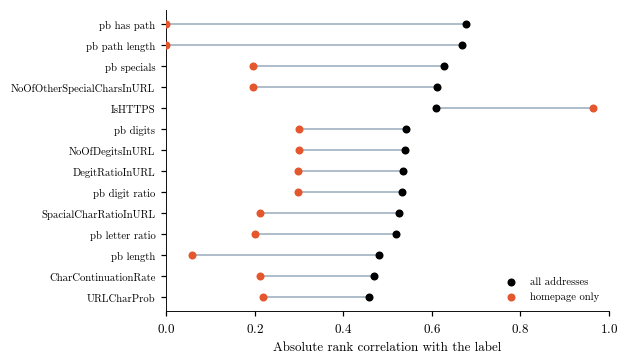

                            toan_bo  trang_chu          nhom
pb_has_path                   0.678        NaN  prefix blind
pb_path_length                0.669        NaN  prefix blind
pb_specials                   0.628      0.195  prefix blind
NoOfOtherSpecialCharsInURL    0.612      0.195       address
IsHTTPS                        0.61      0.963       address
pb_digits                     0.541      0.299  prefix blind
NoOfDegitsInURL               0.541      0.299       address
DegitRatioInURL               0.536      0.299       address
pb_digit_ratio                0.532      0.298  prefix blind
SpacialCharRatioInURL         0.527      0.213       address
pb_letter_ratio                0.52      0.202  prefix blind
pb_length                     0.481      0.059  prefix blind
CharContinuationRate          0.469      0.212       address
URLCharProb                   0.459      0.219       address

Cột trở thành hằng số trên nhóm trang chủ: ['HasObfuscation', 'NoOfAmpersandInURL', 

In [11]:
cols = ADDRESS + PREFIX_BLIND
full = df[cols].corrwith(df.phishing, method="spearman").abs()
varying = [c for c in cols if home[c].nunique() > 1]
hp = home[varying].corrwith(home.phishing, method="spearman").abs().reindex(cols)
both = pd.DataFrame({"toan_bo": full, "trang_chu": hp, "nhom": [GROUP_OF[c] for c in cols]}).sort_values("toan_bo", ascending=False)
both.round(3).to_csv(OUT + "table_b4_correlation_full_vs_homepage.csv", index_label="feature")
top = both.head(14).iloc[::-1]
fig, ax = plt.subplots(figsize=(5.6, 3.2), layout="constrained")
yy = np.arange(len(top))
ax.hlines(yy, top.trang_chu.fillna(0), top.toan_bo, color=GREY, lw=1.2)
ax.scatter(top.toan_bo, yy, color="black", s=18, label="all addresses", zorder=3)
ax.scatter(top.trang_chu.fillna(0), yy, color=OURS, s=18, label="homepage only", zorder=3)
ax.set_yticks(yy)
ax.set_yticklabels([c.replace("_", " ") for c in top.index], fontsize=7)
ax.set_xlim(0, 1)
ax.set_xlabel("Absolute rank correlation with the label")
ax.legend(frameon=False, fontsize=7, loc="lower right")
save(fig, "b4_correlation_dumbbell")
print(both.head(14).round(3).to_string())
print("\nCột trở thành hằng số trên nhóm trang chủ:", sorted(set(cols) - set(varying)))

**Nhận xét:** hầu hết đặc trưng mất phần lớn tương quan khi chỉ xét trang chủ: `pb_specials` từ 0,628 xuống 0,195, `pb_digits` từ 0,541 xuống 0,299, `pb_length` từ 0,481 xuống 0,059. Hai cột đường dẫn trở thành hằng số và bị loại hẳn. Chỉ một đặc trưng đi ngược lại: `IsHTTPS` tăng từ 0,61 lên 0,963, vì trang chủ lừa đảo hầu như không dùng https.
**Quyết định ở Bước 6:** bộ không thấy tiền tố không có `IsHTTPS`. Nếu bộ địa chỉ của tác giả vẫn đạt điểm gần trần trên nhóm trang chủ còn bộ không thấy tiền tố thì không, phần chênh chính là phần đóng góp của `IsHTTPS`.

## 4.11 Quan hệ: các lối tắt có trùng nhau không
Ô dưới xét ba lối tắt trên 100.520 địa chỉ lừa đảo: không bắt đầu bằng `https://www.`, có đường dẫn, và chỉ số tương đồng dưới 100. Mỗi địa chỉ lừa đảo nhận một tổ hợp ba số 0 hoặc 1, rồi ô đếm số địa chỉ của từng tổ hợp.
Cách đọc: tổ hợp (0, 0, 0) là địa chỉ lừa đảo mà không lối tắt nào bắt được. Nếu tổ hợp này gần như rỗng thì bỏ một lối tắt vẫn còn hai lối tắt kia làm thay. Bảng lưu ở `Outputs/table_b4_shortcut_overlap.csv`.

In [12]:
ph = df[df.phishing == 1]
combo = pd.DataFrame({"tien_to": 1 - ph.starts_https_www, "duong_dan": ph.has_path, "chi_so": (ph.URLSimilarityIndex < 100).astype(int)})
counts = combo.value_counts().rename("so_dia_chi").reset_index()
counts["ty_le_pct"] = 100 * counts.so_dia_chi / len(ph)
counts = counts.sort_values("so_dia_chi", ascending=False)
counts.round(2).to_csv(OUT + "table_b4_shortcut_overlap.csv", index=False)
print("Địa chỉ lừa đảo theo ba lối tắt (1 = lối tắt gắn cờ lừa đảo):")
print(counts.round(2).to_string(index=False))
none = counts[(counts.tien_to == 0) & (counts.duong_dan == 0) & (counts.chi_so == 0)].so_dia_chi.sum()
print("\nĐịa chỉ lừa đảo không bị lối tắt nào gắn cờ: %d (%.2f%%)" % (none, 100 * none / len(ph)))
print("Bị cả ba lối tắt gắn cờ: %.2f%% | chỉ chỉ số tương đồng bắt được mà hai quy tắc viết tay bỏ sót: %d địa chỉ"
      % (100 * combo.all(axis=1).mean(), int(((combo.tien_to == 0) & (combo.duong_dan == 0) & (combo.chi_so == 1)).sum())))

Địa chỉ lừa đảo theo ba lối tắt (1 = lối tắt gắn cờ lừa đảo):
 tien_to  duong_dan  chi_so  so_dia_chi  ty_le_pct
       1          1       1       58164      57.86
       1          0       1       39144      38.94
       0          1       1        1813        1.8
       1          0       0         742       0.74
       0          0       1         613       0.61
       1          1       0          25       0.02
       0          0       0          14       0.01
       0          1       0           5          0

Địa chỉ lừa đảo không bị lối tắt nào gắn cờ: 14 (0.01%)
Bị cả ba lối tắt gắn cờ: 57.86% | chỉ chỉ số tương đồng bắt được mà hai quy tắc viết tay bỏ sót: 613 địa chỉ


**Nhận xét:** 57,86% địa chỉ lừa đảo bị cả ba lối tắt gắn cờ và 38,94% bị hai lối tắt (tiền tố và chỉ số tương đồng). Chỉ 14 địa chỉ lừa đảo (0,01%) thoát cả ba. Chỉ số tương đồng bắt thêm 613 địa chỉ mà hai quy tắc viết tay bỏ sót.
Ba lối tắt vì vậy gần như thay thế được cho nhau.
**Quyết định ở Bước 6:** bỏ riêng chỉ số tương đồng (bộ số 2) sẽ gần như không đổi điểm số, vì tiền tố và đường dẫn vẫn còn trong các cột khác. Chỉ có bộ bỏ đồng thời cả ba (bộ không thấy tiền tố chấm trên nhóm trang chủ) mới đo được phần điểm số không dựa vào lối tắt.

## 4.12 Địa lý: tỷ lệ lừa đảo theo TLD mã nước
Ô dưới vẽ tỷ lệ lừa đảo của 32 TLD mã nước có từ 500 địa chỉ, xếp từ thấp tới cao. Cột san hô là TLD trên 50% lừa đảo, đường đứt là tỷ lệ chung của cả bảng.
Cách đọc: đây là nơi đăng ký tên miền, không phải nơi đặt máy chủ hay nơi người lập trang sống (xem Bước 2, mục 2.8). Hình cho biết TLD nào bị dùng nhiều để lừa đảo trong bộ dữ liệu này.

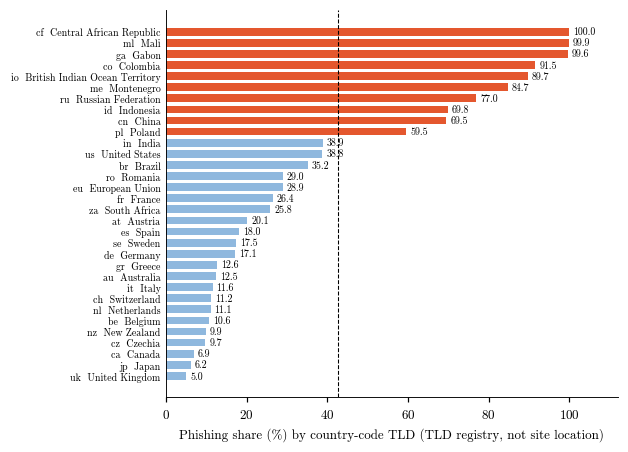

Số TLD mã nước có từ 500 địa chỉ: 32 | trên 50% lừa đảo: 10 | dưới 15%: 11
Hệ số tương quan hạng giữa số địa chỉ và tỷ lệ lừa đảo của 32 TLD: 0.101


In [13]:
cc = df[df.tld_type == "country code"].groupby(["tld_clean", "country"]).agg(dia_chi=("phishing", "size"), lua_dao_pct=("phishing", lambda v: 100 * v.mean()))
cc = cc[cc.dia_chi >= 500].sort_values("lua_dao_pct").reset_index()
fig, ax = plt.subplots(figsize=(5.6, 4.0), layout="constrained")
ax.barh([f"{t}  {c[:30]}" for t, c in zip(cc.tld_clean, cc.country)], cc.lua_dao_pct, color=[OURS if v >= 50 else SKY for v in cc.lua_dao_pct], height=0.7)
ax.axvline(100 * y.mean(), color="black", lw=0.7, ls="--")
for k, v in enumerate(cc.lua_dao_pct):
    ax.text(v + 1, k, f"{v:.1f}", va="center", fontsize=6.5, fontfamily=BOLD)
ax.set_xlim(0, 112)
ax.tick_params(axis="y", length=0, labelsize=6.5)
ax.set_xlabel("Phishing share (%) by country-code TLD (TLD registry, not site location)")
save(fig, "b4_country_tld")
print("Số TLD mã nước có từ 500 địa chỉ:", len(cc), "| trên 50%% lừa đảo: %d | dưới 15%%: %d" % ((cc.lua_dao_pct > 50).sum(), (cc.lua_dao_pct < 15).sum()))
print("Hệ số tương quan hạng giữa số địa chỉ và tỷ lệ lừa đảo của 32 TLD: %.3f" % cc.dia_chi.corr(cc.lua_dao_pct, method="spearman"))

**Nhận xét:** 10 TLD mã nước có trên 50% lừa đảo, đứng đầu là `.cf`, `.ml`, `.ga` (99,6% tới 100%) và `.co`, `.io` (trên 89%). 11 TLD dưới 15%, thấp nhất là `.uk` (5,0%) và `.jp` (6,2%). Tỷ lệ lừa đảo không đi theo số địa chỉ của TLD (tương quan hạng 0,101).
Khác biệt giữa các TLD rất lớn, nhưng nó phản ánh chính sách đăng ký (TLD từng cấp miễn phí, TLD bán như tên chung) chứ không phản ánh nước nào lừa đảo nhiều hơn.
**Quyết định ở Bước 6:** không thêm đặc trưng nước hay vùng. Thông tin TLD đã có sẵn trong `TLDLegitimateProb` và độ dài TLD, và phép thử TLD chưa thấy đo đúng rủi ro của việc học theo TLD.

## 4.13 Địa lý: lối tắt có yếu đi theo loại TLD không
Ô dưới chia bảng theo loại TLD (chung, mã nước, địa chỉ IP) và theo có phải trang chủ không, rồi tính tỷ lệ lừa đảo cùng tỷ lệ bắt được và báo động giả của quy tắc tiền tố trong từng ô.
Cách đọc: nếu quy tắc tiền tố bắt được gần như nhau ở mọi loại TLD thì lối tắt không gắn với địa lý, mà gắn với cách thu thập. Bảng lưu ở `Outputs/table_b4_tld_type_homepage.csv`.

In [14]:
flag = 1 - df.starts_https_www                                                      # quy tắc tiền tố
geo = df.assign(flag=flag).groupby(["tld_type", "homepage_only"]).agg(
    dia_chi=("phishing", "size"),
    lua_dao_pct=("phishing", lambda v: 100 * v.mean()),
    quy_tac_bat_duoc_pct=("flag", lambda f: 100 * f[df.loc[f.index, "phishing"] == 1].mean()),
    quy_tac_bao_dong_gia_pct=("flag", lambda f: 100 * f[df.loc[f.index, "phishing"] == 0].mean()))
geo.round(2).to_csv(OUT + "table_b4_tld_type_homepage.csv")
print(geo.round(2).to_string())
print("\nÔ trống (NaN) ở cột báo động giả nghĩa là nhóm ấy không có địa chỉ hợp lệ nào để chặn nhầm.")

                            dia_chi  lua_dao_pct  quy_tac_bat_duoc_pct  quy_tac_bao_dong_gia_pct
tld_type     homepage_only                                                                      
country code 0                16443          100                  97.4                       NaN
             1                52433        23.87                 98.83                         0
generic      0                42937          100                 96.76                       NaN
             1               122921        22.77                 98.28                         0
ip address   0                  627          100                   100                       NaN
             1                    9          100                   100                       NaN

Ô trống (NaN) ở cột báo động giả nghĩa là nhóm ấy không có địa chỉ hợp lệ nào để chặn nhầm.


**Nhận xét:** quy tắc tiền tố bắt từ 96,76% tới 100% địa chỉ lừa đảo ở cả sáu ô và không báo động giả ở bất kỳ ô nào có địa chỉ hợp lệ. Ở nhóm trang chủ, TLD mã nước và TLD chung có tỷ lệ lừa đảo gần nhau (23,87% và 22,77%) và quy tắc bắt gần như nhau (98,83% và 98,28%). Mọi địa chỉ có đường dẫn đều là lừa đảo, ở mọi loại TLD.
**Quyết định ở Bước 6:** phép thử TLD chưa thấy không làm lối tắt yếu đi, nên không thay được việc bỏ cột. Kết quả TLD chưa thấy ở Bước 6 sẽ được báo cáo cho cả bộ đủ đặc trưng lẫn bộ không thấy tiền tố.

## 4.14 Trang lừa đảo nhỏ cỡ nào so với trang hợp lệ
Ô dưới vẽ biểu đồ tần suất của log số dòng mã HTML và log(1 + số liên kết ra ngoài), tách theo lớp, rồi đếm tỷ lệ trang dưới 10, 50 và 100 dòng mã, và tính ROC-AUC của `LineOfCode` khi dùng một mình.
Cách đọc: hai khối tách hẳn nhau nghĩa là chỉ cần đếm số dòng mã là biết lớp. Đây là kiểm tra lại ý "trang lừa đảo đã chết khi được lưu" của Bước 2 và Bước 3.

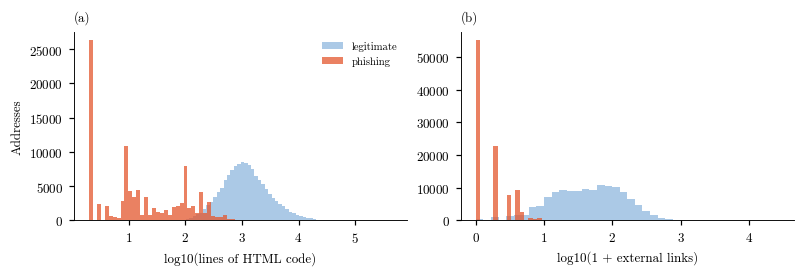

Dưới  10 dòng mã: hợp lệ 0.00% | lừa đảo 45.70%
Dưới  50 dòng mã: hợp lệ 0.00% | lừa đảo 68.25%
Dưới 100 dòng mã: hợp lệ 0.00% | lừa đảo 76.78%
Trang lừa đảo là trang chủ: dưới 50 dòng mã 91.5% | không có liên kết ngoài 72.8%
ROC-AUC của LineOfCode một mình: toàn bộ 0.9903 | nhóm trang chủ 0.9984


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.4), layout="constrained")
for cls, color in [(0, SKY), (1, OURS)]:
    v = df.loc[y == cls]
    axes[0].hist(np.log10(v.LineOfCode), bins=60, color=color, alpha=0.75, label=CLASS[cls])
    axes[1].hist(np.log10(1 + v.NoOfExternalRef), bins=40, color=color, alpha=0.75, label=CLASS[cls])
axes[0].set_xlabel("log10(lines of HTML code)")
axes[0].set_ylabel("Addresses")
axes[1].set_xlabel("log10(1 + external links)")
axes[0].legend(frameon=False, fontsize=7)
panel(axes[0], "(a)")
panel(axes[1], "(b)")
save(fig, "b4_page_size")
for cut in [10, 50, 100]:
    print("Dưới %3d dòng mã: hợp lệ %.2f%% | lừa đảo %.2f%%" % (cut, 100 * (df.loc[y == 0, "LineOfCode"] < cut).mean(), 100 * (df.loc[y == 1, "LineOfCode"] < cut).mean()))
ph_home = df[(y == 1) & (df.homepage_only == 1)]
print("Trang lừa đảo là trang chủ: dưới 50 dòng mã %.1f%% | không có liên kết ngoài %.1f%%" % (100 * (ph_home.LineOfCode < 50).mean(), 100 * (ph_home.NoOfExternalRef == 0).mean()))
print("ROC-AUC của LineOfCode một mình: toàn bộ %.4f | nhóm trang chủ %.4f" % (1 - roc_auc_score(y, df.LineOfCode), 1 - roc_auc_score(home.phishing, home.LineOfCode)))

**Nhận xét:** không trang hợp lệ nào có dưới 100 dòng mã, trong khi 45,70% trang lừa đảo có dưới 10 dòng, 68,25% dưới 50 dòng và 76,78% dưới 100 dòng. Ở trang lừa đảo là trang chủ, tỷ lệ dưới 50 dòng lên tới 91,5%. `LineOfCode` một mình đạt ROC-AUC 0,9903 trên toàn bộ và 0,9984 trên nhóm trang chủ, tức nhóm trang còn mạnh hơn khi bỏ đường dẫn.
**Quyết định ở Bước 6:** nhóm đặc trưng trang được đọc như một lối tắt của cách thu thập (trang lừa đảo được lưu khi đã trống), không phải bằng chứng mô hình hiểu nội dung trang. Bộ "chỉ có trang" vẫn chạy để so, nhưng bộ lọc cho tin nhắn chỉ được dùng đặc trưng địa chỉ.

## 4.15 Ghi lại điều rút ra
Bảng dưới gom 14 điều rút ra và quyết định tương ứng. Nhóm cần cập nhật bảng này nếu dữ liệu đổi.

| STT | Điều rút ra | Con số | Quyết định ở Bước 6 |
|---|---|---|---|
| 1 | Đặc trưng lệch phải rất mạnh | 30 trên 43 đặc trưng có độ lệch trên 2; độ dài từ 53,70 xuống 2,37 sau log | Mô hình tuyến tính, k-NN, MLP dùng log(1 + x) rồi chuẩn hoá |
| 2 | Bảy đặc trưng một mình đã gần tách trọn | Chỉ số tương đồng 0,9961, `LineOfCode` 0,9903 | Thang đặc trưng tách riêng chỉ số tương đồng và nhóm trang |
| 3 | Cột của tác giả trùng cột tự tính | Tương quan 0,989 tới 0,999 | Đọc kết quả theo nhóm, không theo từng cột |
| 4 | Ở nhóm trang chủ, đặc trưng không thấy tiền tố gần như không tách | ROC-AUC một mình 0,54 tới 0,589 | Chấm riêng mọi mô hình trên nhóm trang chủ |
| 5 | Lừa đảo tập trung trên tên miền dùng chung | 62,1% địa chỉ lừa đảo so với 3,8% hợp lệ | Thêm cách chia theo tên miền |
| 6 | TLD chưa thấy lệch phân bố, lớp hợp lệ lệch nhiều hơn | 12 trên 35 đặc trưng lệch quá 0,5 độ lệch chuẩn | Thử TLD chưa thấy, có bộ bỏ thống kê TLD |
| 7 | Không có thời gian, tệp đã được trộn | Tỷ lệ lừa đảo theo khối từ 38,5% tới 44,2% | Không chia theo thời gian; ghi là giới hạn |
| 8 | Độ dài chỉ tách được nhóm có đường dẫn | Cùng trung vị 15 ký tự ở nhóm trang chủ | Báo cáo theo nhóm trang chủ |
| 9 | Ngưỡng độ dài cũng là lối tắt | 19,4% địa chỉ lừa đảo dài hơn địa chỉ hợp lệ dài nhất (46 ký tự) | Ghi trong bài |
| 10 | Tương quan sụp ở nhóm trang chủ, trừ `IsHTTPS` | `IsHTTPS` từ 0,61 lên 0,963 | Bộ không thấy tiền tố bỏ `IsHTTPS` |
| 11 | Ba lối tắt gần như thay thế cho nhau | Chỉ 14 địa chỉ lừa đảo (0,01%) thoát cả ba | Phải bỏ cả nhóm, bỏ một lối tắt chưa đủ |
| 12 | TLD mã nước khác nhau rất xa | Từ 5,0% (`.uk`) tới 100% (`.cf`) | TLD mã nước chỉ để mô tả |
| 13 | Lối tắt không yếu đi theo loại TLD | Quy tắc tiền tố bắt từ 96,76% tới 100% | Phép thử TLD chưa thấy không thay được việc bỏ cột |
| 14 | Trang lừa đảo nhỏ hơn hẳn | 68,25% dưới 50 dòng mã so với 0% | Nhóm trang được đọc như lối tắt |